CRS Regiones: EPSG:4326
CRS Red Vial: EPSG:4326
CRS Puntos: EPSG:4326
CRS Puntos: EPSG:4326


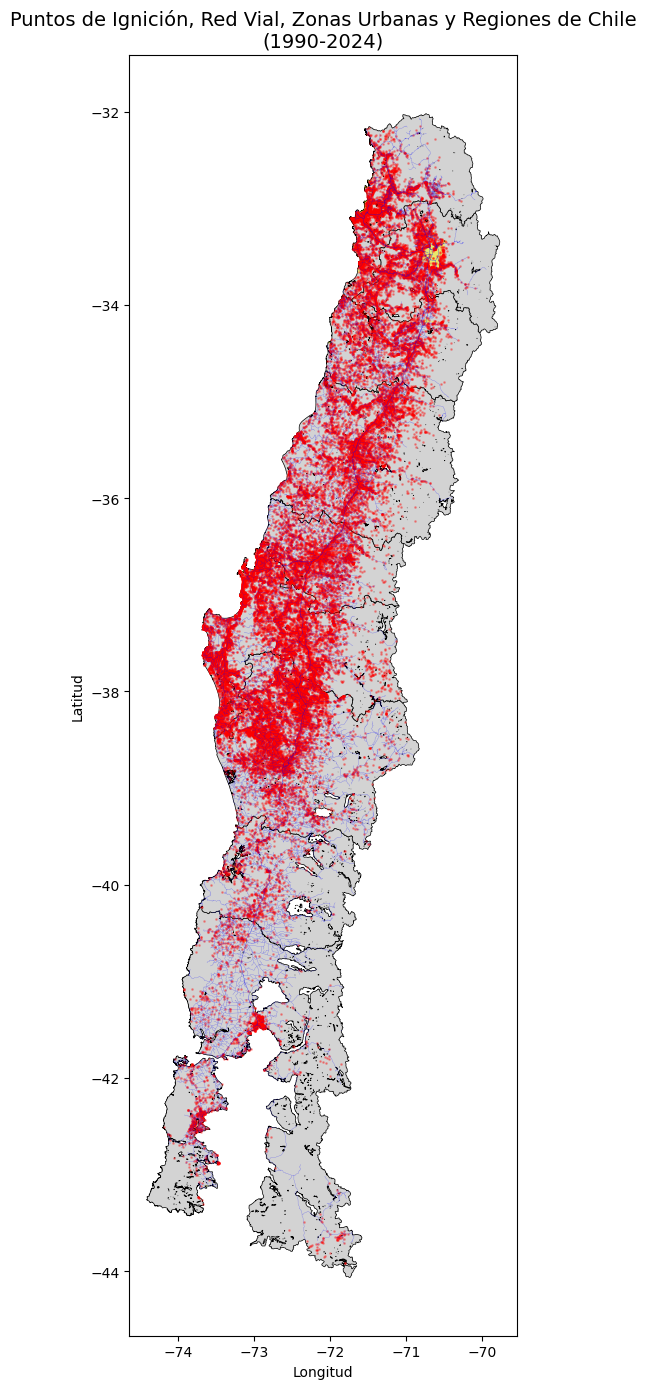

In [8]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Leer los datos
temp_puntos = gpd.read_file("C:/Users/scray/Documentos/puntos_ignicion_1990_2024_corregidos2025.shp")
temp_red_vial = gpd.read_file("C:/Users/scray/Documentos/red_vial_chile_aoi.shp")
temp_regiones = gpd.read_file("C:/Users/scray/Documentos/regiones_sin_agua_2025.shp")
temp_urbano = gpd.read_file("C:/Users/scray/Documentos/areas_urbanas_2025.shp")
# ============================================
# IMPORTANTE: Unificar todos los CRS a EPSG:4326
# ============================================
temp_regiones = temp_regiones.to_crs(epsg=4326)
temp_red_vial = temp_red_vial.to_crs(epsg=4326)
temp_puntos = temp_puntos.to_crs(epsg=4326)
temp_urbano = temp_urbano.to_crs(epsg=4326)

# Verificar que ahora todos tienen el mismo CRS
print("CRS Regiones:", temp_regiones.crs)
print("CRS Red Vial:", temp_red_vial.crs)
print("CRS Puntos:", temp_puntos.crs)
print("CRS Puntos:", temp_urbano.crs)

# ============================================
# Graficar
# ============================================
fig, ax = plt.subplots(figsize=(10, 14))

# Primero las regiones (capa base)
temp_regiones.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5)

# Luego la red vial
temp_red_vial.plot(ax=ax, color='blue', linewidth=0.2, alpha=0.5)

# Luego la zona urbana
temp_urbano.plot(ax=ax, color='yellow', linewidth=0.2, alpha=0.5)

# Finalmente los puntos de ignición (más pequeños por la cantidad)
temp_puntos.plot(ax=ax, color='red', markersize=1, alpha=0.3)

ax.set_title('Puntos de Ignición, Red Vial, Zonas Urbanas y Regiones de Chile\n(1990-2024)', fontsize=14)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')

plt.tight_layout()
plt. show()

   REGION Temporada  ignicion  year  objectid  cir_sena  codregion  \
0  Biobio      2018       1.0  2018      1096        10          8   
1  Biobio      2018       1.0  2018      1096        10          8   
2  Biobio      2018       1.0  2018      1096        10          8   
3  Biobio      2018       1.0  2018      1096        10          8   
4  Biobio      2018       1.0  2018      1096        10          8   

        area_km    st_area_sh    st_length_            Region_2  \
0  24021.621594  3.817612e+10  2.097147e+06  Región del Bío-Bío   
1  24021.621594  3.817612e+10  2.097147e+06  Región del Bío-Bío   
2  24021.621594  3.817612e+10  2.097147e+06  Región del Bío-Bío   
3  24021.621594  3.817612e+10  2.097147e+06  Región del Bío-Bío   
4  24021.621594  3.817612e+10  2.097147e+06  Región del Bío-Bío   

                             geometry  
0  MULTIPOINT ((-73.53472 -37.67528))  
1  MULTIPOINT ((-73.54194 -37.79778))  
2  MULTIPOINT ((-73.53448 -37.67835))  
3  MULTIPOINT ((

<Axes: >

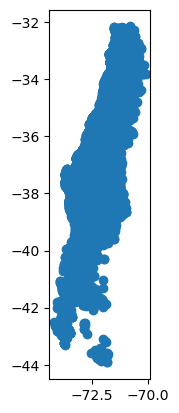

In [9]:
print(temp_puntos.head())  # Muestra los primeros registros de puntos de ignición
print(temp_puntos.columns)  # Columnas disponibles (por ejemplo, fechas, causas?)
temp_puntos.plot()  # Visualización rápida de los puntos

In [12]:
import geopandas as gpd
from shapely.geometry import Point, MultiPoint

# Asumiendo que ya tienes temp_puntos cargado...

# Función para extraer el punto único de MultiPoint
def extract_single_point(geom):
    if isinstance(geom, MultiPoint) and len(geom.geoms) == 1:
        return geom.geoms[0]  # Retorna el Point único
    else:
        return geom  # Mantiene como está si no es MultiPoint o tiene más de uno

# Aplica la transformación
temp_puntos['geometry'] = temp_puntos['geometry'].apply(extract_single_point)

# Verifica los tipos de geometría después de la transformación
print(temp_puntos.geom_type.value_counts())  # Debería mostrar 'Point' para todos si eran singles

# Opcional: Si quieres explotar MultiPoints con múltiples puntos en rows separados
# temp_puntos = temp_puntos.explode(ignore_index=True)

Point    50016
Name: count, dtype: int64


Conteo de igniciones por región:
 REGION
Biobio           14790
La Araucania     10929
Maule             6596
Valparaiso        4565
Ñuble             3825
Metropolitana     3494
O'Higgins         3073
Los Lagos         1812
Los Rios           932
Name: count, dtype: int64
Conteo de igniciones por año:
 year
1990     165
1991     340
1992     178
1993     290
1994     328
1995     251
1996     269
1997     314
1998     298
1999     367
2000     195
2001     184
2002     444
2003     374
2004     396
2005     419
2006     243
2007     205
2008     389
2009     463
2010     291
2011     289
2012     317
2013     262
2014     463
2015     783
2016     467
2017     579
2018    7471
2019    7924
2020    6842
2021    6720
2022    6756
2023    4740
Name: count, dtype: int64
Tabla de igniciones por región y año:
 year           1990  1991  1992  1993  1994  1995  1996  1997  1998  1999  \
REGION                                                                      
Biobio           13    57    

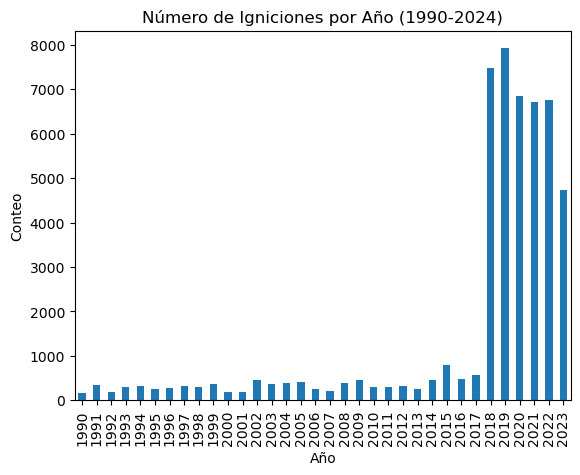

In [13]:
# Conteo por región
conteo_por_region = temp_puntos['REGION'].value_counts()
print("Conteo de igniciones por región:\n", conteo_por_region)

# Conteo por año
conteo_por_ano = temp_puntos['year'].value_counts().sort_index()
print("Conteo de igniciones por año:\n", conteo_por_ano)

# Tabla pivote: igniciones por región y año
pivot = temp_puntos.pivot_table(index='REGION', columns='year', aggfunc='size', fill_value=0)
print("Tabla de igniciones por región y año:\n", pivot)

# Gráfico de barras para años
import matplotlib.pyplot as plt
conteo_por_ano.plot(kind='bar')
plt.title('Número de Igniciones por Año (1990-2024)')
plt.xlabel('Año')
plt.ylabel('Conteo')
plt.show()

In [14]:
import geopandas as gpd
from shapely.ops import unary_union
import matplotlib.pyplot as plt

# Reproyectar a UTM 19S
utm_crs = 'EPSG:32719'
temp_puntos_utm = temp_puntos.to_crs(utm_crs)
temp_regiones_utm = temp_regiones.to_crs(utm_crs)
temp_red_vial_utm = temp_red_vial.to_crs(utm_crs)
temp_urbano_utm = temp_urbano.to_crs(utm_crs)

# Ajusta si la columna de regiones es 'NOMBRE' en lugar de 'REGION'
temp_regiones_utm = temp_regiones_utm.rename(columns={'NOMBRE': 'REGION'})  # Si es necesario

C:\Users\scray\AppData\Local\Temp\ipykernel_15624\66263888.py:11: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()


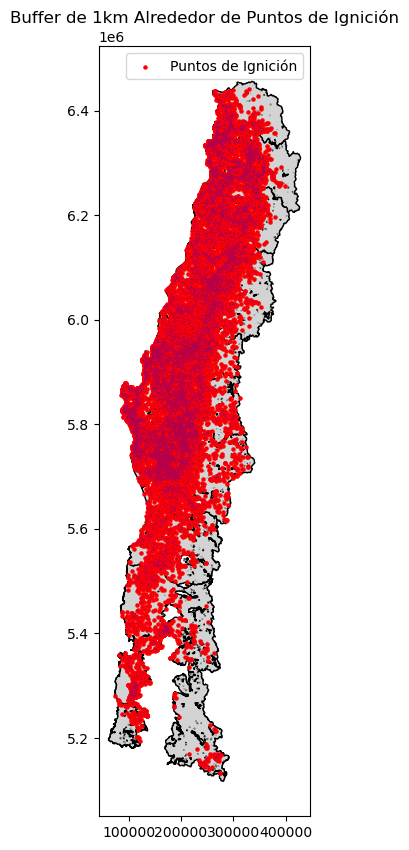

In [15]:
# Crear buffer de presencias
buffer_presence = temp_puntos_utm.buffer(1000)  # 1km
union_buffer_presence = unary_union(buffer_presence)

# Visualizar
fig1, ax1 = plt.subplots(figsize=(10, 10))
temp_regiones_utm.plot(ax=ax1, color='lightgrey', edgecolor='black')
temp_puntos_utm.plot(ax=ax1, color='red', markersize=5, label='Puntos de Ignición')
gpd.GeoSeries(union_buffer_presence).plot(ax=ax1, color='blue', alpha=0.3, label='Buffer 1km Presencias')
plt.title('Buffer de 1km Alrededor de Puntos de Ignición')
plt.legend()
plt.show()

C:\Users\scray\AppData\Local\Temp\ipykernel_15624\737518701.py:13: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()


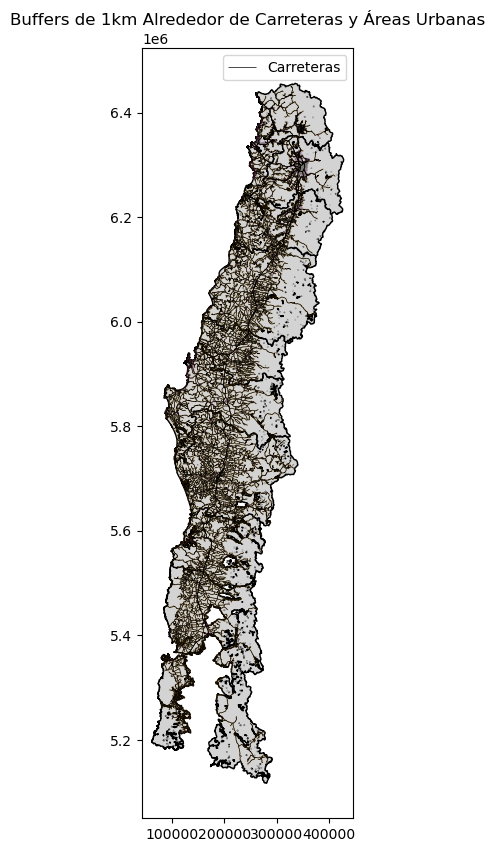

In [35]:
# Buffers de carreteras y urbanas (1km, ajustable)
buffer_roads = temp_red_vial_utm.buffer(1000)
buffer_urban = temp_urbano_utm.buffer(1000)

# Visualizar buffers parciales
fig2, ax2 = plt.subplots(figsize=(10, 10))
temp_regiones_utm.plot(ax=ax2, color='lightgrey', edgecolor='black')
temp_red_vial_utm.plot(ax=ax2, color='black', linewidth=0.5, label='Carreteras')
temp_urbano_utm.plot(ax=ax2, color='green', alpha=0.5, label='Áreas Urbanas')
gpd.GeoSeries(unary_union(buffer_roads)).plot(ax=ax2, color='orange', alpha=0.3, label='Buffer Carreteras')
gpd.GeoSeries(unary_union(buffer_urban)).plot(ax=ax2, color='purple', alpha=0.3, label='Buffer Urbanas')
plt.title('Buffers de 1km Alrededor de Carreteras y Áreas Urbanas')
plt.legend()
plt.show()

C:\Users\scray\AppData\Local\Temp\ipykernel_15624\437714644.py:9: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend()
C:\Users\scray\AppData\Local\Temp\ipykernel_15624\437714644.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


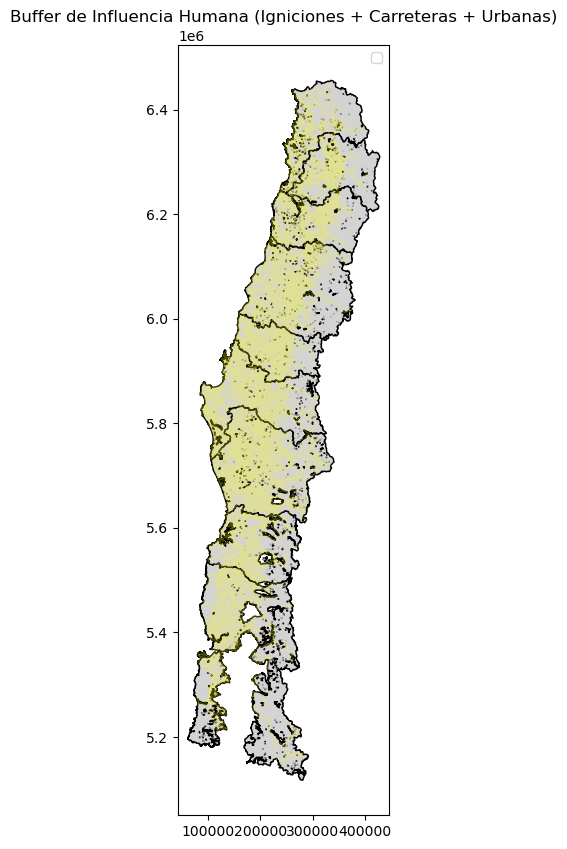

In [36]:
# Unión completa para influencia humana
buffer_influence = unary_union([union_buffer_presence, unary_union(buffer_roads), unary_union(buffer_urban)])

# Visualizar buffer completo
fig3, ax3 = plt.subplots(figsize=(10, 10))
temp_regiones_utm.plot(ax=ax3, color='lightgrey', edgecolor='black')
gpd.GeoSeries(buffer_influence).plot(ax=ax3, color='yellow', alpha=0.3, label='Buffer Influencia Completo')
plt.title('Buffer de Influencia Humana (Igniciones + Carreteras + Urbanas)')
plt.legend()
plt.show()

In [37]:
print(temp_regiones_utm.columns)
print(temp_regiones_utm.head())  # Para ver una muestra de los datos

Index(['objectid', 'cir_sena', 'codregion', 'area_km', 'st_area_sh',
       'st_length_', 'Region', 'geometry'],
      dtype='object')
   objectid  cir_sena  codregion       area_km    st_area_sh    st_length_  \
0      1091         6          5  16322.970393  2.301475e+10  1.679609e+06   
1      1091         6          5  16322.970393  2.301475e+10  1.679609e+06   
2      1091         6          5  16322.970393  2.301475e+10  1.679609e+06   
3      1091         6          5  16322.970393  2.301475e+10  1.679609e+06   
4      1091         6          5  16322.970393  2.301475e+10  1.679609e+06   

                 Region                                           geometry  
0  Región de Valparaíso  POLYGON ((257306.458 6284692.246, 257302.919 6...  
1  Región de Valparaíso  POLYGON ((247871.742 6324266.135, 247873.322 6...  
2  Región de Valparaíso  POLYGON ((262587.743 6370421.513, 262586 63704...  
3  Región de Valparaíso  POLYGON ((262042.813 6371028.605, 262045.137 6...  
4  Región d

In [32]:
print(temp_regiones_utm['Region'].unique())

['Región de Valparaíso' 'Región Metropolitana de Santiago'
 'Región de Los Lagos' 'Región de Los Ríos' 'Región de La Araucanía'
 'Región del Bío-Bío' 'Región de Ñuble' 'Región del Maule'
 "Región del Libertador Bernardo O'Higgins"]


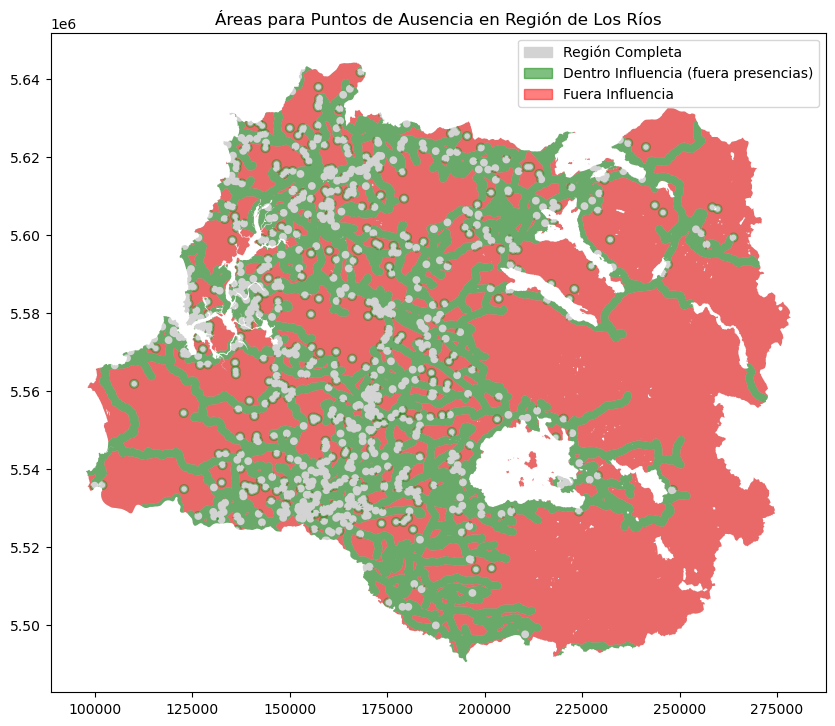

Area inside vacía? False
Area outside vacía? False


In [38]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch  # Para handles manuales si es necesario
import geopandas as gpd
from shapely import union_all  # Importa directamente para union_all

# Ejemplo para una región (ajusta el nombre)
region_example = 'Región de Los Ríos'
# Usa union_all() en lugar de unary_union
region_poly = union_all(temp_regiones_utm[temp_regiones_utm['Region'] == region_example].geometry)  # Ajusta 'Region' si es 'REGION'

# Áreas para sampling
area_inside = region_poly.difference(union_buffer_presence).intersection(buffer_influence)
area_outside = region_poly.difference(buffer_influence)

# Visualizar con handles explícitos para legend
fig4, ax4 = plt.subplots(figsize=(10, 10))

# Plot región completa
region_plot = gpd.GeoSeries(region_poly).plot(ax=ax4, color='lightgrey', label='Región Completa')

# Plot area_inside (verde)
inside_plot = gpd.GeoSeries(area_inside).plot(ax=ax4, color='green', alpha=0.5, label='Dentro Influencia (fuera presencias)')

# Plot area_outside (rojo)
outside_plot = gpd.GeoSeries(area_outside).plot(ax=ax4, color='red', alpha=0.5, label='Fuera Influencia')

# Crear legend con handles (usa el primer artista de cada colección)
handles = [
    Patch(color='lightgrey', label='Región Completa'),
    Patch(color='green', alpha=0.5, label='Dentro Influencia (fuera presencias)'),
    Patch(color='red', alpha=0.5, label='Fuera Influencia')
]
plt.legend(handles=handles)

plt.title(f'Áreas para Puntos de Ausencia en {region_example}')
plt.show()

# Opcional: Verifica si áreas no están vacías
print(f'Area inside vacía? {area_inside.is_empty}')
print(f'Area outside vacía? {area_outside.is_empty}')

In [39]:
# Nombres únicos de regiones
regiones_unicas = temp_regiones_utm['Region'].unique()

print("Regiones únicas en temp_regiones_utm:")
print("=" * 60)
for i, region in enumerate(regiones_unicas, 1):
    print(f"{i}. {region}")

print(f"\nTotal de regiones: {len(regiones_unicas)}")

Regiones únicas en temp_regiones_utm:
1. Región de Valparaíso
2. Región Metropolitana de Santiago
3. Región de Los Lagos
4. Región de Los Ríos
5. Región de La Araucanía
6. Región del Bío-Bío
7. Región de Ñuble
8. Región del Maule
9. Región del Libertador Bernardo O'Higgins

Total de regiones: 9


In [40]:
from shapely.ops import unary_union
from shapely import union_all
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Lista de todas las regiones
regiones_lista = temp_regiones_utm['Region'].unique(). tolist()

print("Regiones a procesar:")
for r in regiones_lista:
    print(f"  - {r}")

# ============================================
# PROCESAR TODAS LAS REGIONES
# ============================================
resultados_areas = {}

for region_name in regiones_lista:
    print(f"\nProcesando: {region_name}")
    
    # Obtener polígono de la región
    region_poly = union_all(temp_regiones_utm[temp_regiones_utm['Region'] == region_name]. geometry)
    
    # Áreas para sampling
    area_inside = region_poly.difference(union_buffer_presence).intersection(buffer_influence)
    area_outside = region_poly.difference(buffer_influence)
    
    # Guardar resultados
    resultados_areas[region_name] = {
        'region_poly': region_poly,
        'area_inside': area_inside,
        'area_outside': area_outside,
        'inside_empty': area_inside.is_empty,
        'outside_empty': area_outside.is_empty
    }
    
    print(f"  - Área inside vacía: {area_inside.is_empty}")
    print(f"  - Área outside vacía: {area_outside.is_empty}")

# ============================================
# RESUMEN
# ============================================
print("\n" + "=" * 60)
print("RESUMEN DE ÁREAS POR REGIÓN")
print("=" * 60)
for region, datos in resultados_areas.items():
    status_inside = "✗ Vacía" if datos['inside_empty'] else "✓ OK"
    status_outside = "✗ Vacía" if datos['outside_empty'] else "✓ OK"
    print(f"{region}:")
    print(f"    Inside:  {status_inside}")
    print(f"    Outside: {status_outside}")

Regiones a procesar:
  - Región de Valparaíso
  - Región Metropolitana de Santiago
  - Región de Los Lagos
  - Región de Los Ríos
  - Región de La Araucanía
  - Región del Bío-Bío
  - Región de Ñuble
  - Región del Maule
  - Región del Libertador Bernardo O'Higgins

Procesando: Región de Valparaíso
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región Metropolitana de Santiago
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región de Los Lagos
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región de Los Ríos
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región de La Araucanía
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región del Bío-Bío
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región de Ñuble
  - Área inside vacía: False
  - Área outside vacía: False

Procesando: Región del Maule
  - Área inside vacía: False
  - Área outside vac

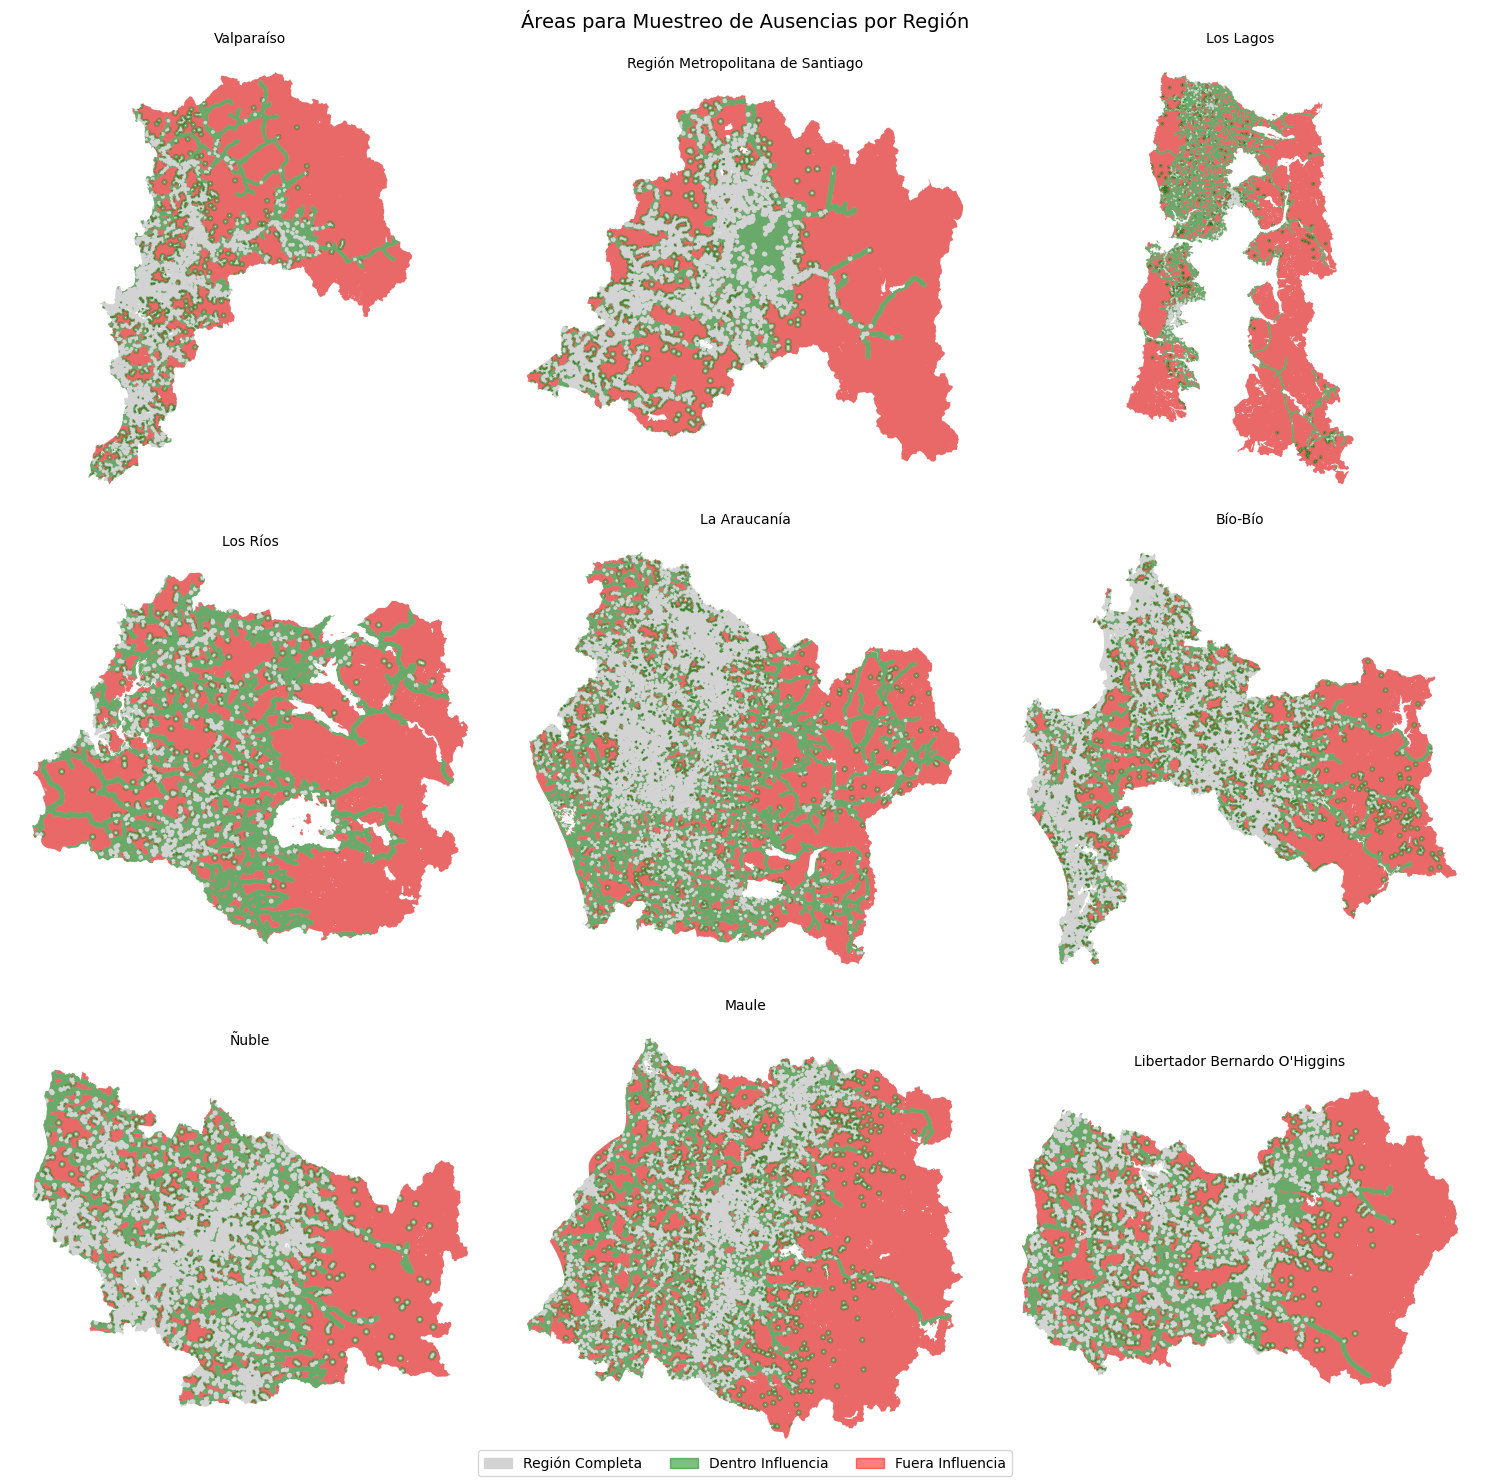

In [41]:
# Crear figura con múltiples subplots
n_regiones = len(regiones_lista)
n_cols = 3
n_rows = (n_regiones + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 5))
axes = axes.flatten()

for idx, region_name in enumerate(regiones_lista):
    ax = axes[idx]
    datos = resultados_areas[region_name]
    
    # Plot región completa
    gpd.GeoSeries(datos['region_poly']).plot(ax=ax, color='lightgrey')
    
    # Plot area_inside (verde)
    if not datos['inside_empty']:
        gpd.GeoSeries(datos['area_inside']).plot(ax=ax, color='green', alpha=0.5)
    
    # Plot area_outside (rojo)
    if not datos['outside_empty']:
        gpd.GeoSeries(datos['area_outside']).plot(ax=ax, color='red', alpha=0.5)
    
    ax.set_title(region_name. replace('Región de ', '').replace('Región del ', ''), fontsize=10)
    ax.set_axis_off()

# Ocultar subplots vacíos
for idx in range(len(regiones_lista), len(axes)):
    axes[idx].set_visible(False)

# Leyenda global
handles = [
    Patch(color='lightgrey', label='Región Completa'),
    Patch(color='green', alpha=0.5, label='Dentro Influencia'),
    Patch(color='red', alpha=0.5, label='Fuera Influencia')
]
fig.legend(handles=handles, loc='lower center', ncol=3, fontsize=10)

plt.suptitle('Áreas para Muestreo de Ausencias por Región', fontsize=14)
plt.tight_layout()
plt.savefig("C:/Users/scray/Documentos/areas_muestreo_regiones.png", dpi=300, bbox_inches='tight')
plt.show()

In [43]:
import geopandas as gpd
import pandas as pd
import numpy as np
from shapely.geometry import Point
from shapely.ops import unary_union
from shapely import union_all
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

# ============================================
# FUNCIÓN PARA GENERAR PUNTOS ALEATORIOS
# ============================================
def generar_puntos_en_area(area, n_puntos, max_intentos_factor=2000):
    """
    Genera n puntos aleatorios dentro de un área
    """
    if area.is_empty:
        return []
    
    puntos = []
    minx, miny, maxx, maxy = area.bounds
    max_intentos = n_puntos * max_intentos_factor
    intentos = 0
    
    while len(puntos) < n_puntos and intentos < max_intentos:
        x = np. random.uniform(minx, maxx)
        y = np. random.uniform(miny, maxy)
        punto = Point(x, y)
        
        if area.contains(punto):
            puntos.append(punto)
        intentos += 1
    
    return puntos

# ============================================
# CALCULAR CONTEO POR AÑO Y REGIÓN
# ============================================
conteo = temp_puntos_utm.groupby(['year', 'REGION']).size().reset_index(name='n_total')

# Mitad para cada tipo de ausencia
conteo['n_dentro'] = (conteo['n_total'] / 2).apply(np.ceil). astype(int)
conteo['n_fuera'] = (conteo['n_total'] / 2).apply(np.floor).astype(int)

print("Puntos a generar por tipo:")
print(f"  Total dentro influencia: {conteo['n_dentro'].sum():,}")
print(f"  Total fuera influencia:  {conteo['n_fuera'].sum():,}")
print(f"  Total ausencias:         {conteo['n_dentro'].sum() + conteo['n_fuera'].sum():,}")

# ============================================
# MAPEO DE NOMBRES DE REGIONES
# ============================================
mapeo_regiones = {
    'Biobio': 'Región del Bío-Bío',
    'La Araucania': 'Región de La Araucanía',
    'Los Lagos': 'Región de Los Lagos',
    'Los Rios': 'Región de Los Ríos',
    'Maule': 'Región del Maule',
    'Metropolitana': 'Región Metropolitana de Santiago',
    "O'Higgins": "Región del Libertador Bernardo O'Higgins",
    'Valparaiso': 'Región de Valparaíso',
    'Ñuble': 'Región de Ñuble'
}

# ============================================
# PREPARAR ÁREAS POR REGIÓN
# ============================================
print("\n" + "=" * 60)
print("PREPARANDO ÁREAS POR REGIÓN...")
print("=" * 60)

areas_por_region = {}

for region_puntos, region_shp in mapeo_regiones.items():
    print(f"\nProcesando: {region_puntos}")
    
    # Polígono de la región
    mask = temp_regiones_utm['Region'] == region_shp
    if not mask.any():
        print(f"  ✗ No se encontró la región")
        continue
    
    region_poly = union_all(temp_regiones_utm[mask].geometry)
    
    # Área DENTRO de influencia humana (pero fuera del buffer de presencias)
    area_dentro = region_poly.intersection(buffer_influence). difference(union_buffer_presence)
    
    # Área FUERA de influencia humana
    area_fuera = region_poly.difference(buffer_influence)
    
    # Calcular superficies (km²)
    area_dentro_km2 = area_dentro. area / 1e6 if not area_dentro.is_empty else 0
    area_fuera_km2 = area_fuera.area / 1e6 if not area_fuera. is_empty else 0
    
    areas_por_region[region_puntos] = {
        'area_dentro': area_dentro,
        'area_fuera': area_fuera,
        'area_dentro_km2': area_dentro_km2,
        'area_fuera_km2': area_fuera_km2
    }
    
    print(f"  Área dentro influencia: {area_dentro_km2:,.1f} km²")
    print(f"  Área fuera influencia:  {area_fuera_km2:,.1f} km²")
    
    if area_dentro. is_empty:
        print(f"  ⚠️ SIN área dentro de influencia")
    if area_fuera.is_empty:
        print(f"  ⚠️ SIN área fuera de influencia")

# ============================================
# GENERAR PUNTOS DE AUSENCIA
# ============================================
print("\n" + "=" * 60)
print("GENERANDO PUNTOS DE AUSENCIA...")
print("=" * 60)

lista_ausencias = []
total_dentro = 0
total_fuera = 0
ajustes = []

for idx, row in conteo.iterrows():
    year = row['year']
    region = row['REGION']
    n_dentro = row['n_dentro']
    n_fuera = row['n_fuera']
    
    if region not in areas_por_region:
        print(f"  ✗ {region} no encontrada")
        continue
    
    areas = areas_por_region[region]
    
    # ============================================
    # Generar puntos DENTRO de influencia
    # ============================================
    if not areas['area_dentro'].is_empty:
        puntos_dentro = generar_puntos_en_area(areas['area_dentro'], n_dentro)
        
        for punto in puntos_dentro:
            lista_ausencias.append({
                'year': year,
                'REGION': region,
                'ignicion': 0,
                'tipo_ausencia': 'dentro_influencia',
                'geometry': punto
            })
        total_dentro += len(puntos_dentro)
        
        # Si no se generaron suficientes, registrar ajuste
        if len(puntos_dentro) < n_dentro:
            faltantes = n_dentro - len(puntos_dentro)
            ajustes.append({
                'year': year,
                'region': region,
                'tipo': 'dentro',
                'solicitados': n_dentro,
                'generados': len(puntos_dentro),
                'faltantes': faltantes
            })
    else:
        ajustes.append({
            'year': year,
            'region': region,
            'tipo': 'dentro',
            'solicitados': n_dentro,
            'generados': 0,
            'faltantes': n_dentro
        })
    
    # ============================================
    # Generar puntos FUERA de influencia
    # ============================================
    if not areas['area_fuera'].is_empty:
        puntos_fuera = generar_puntos_en_area(areas['area_fuera'], n_fuera)
        
        for punto in puntos_fuera:
            lista_ausencias.append({
                'year': year,
                'REGION': region,
                'ignicion': 0,
                'tipo_ausencia': 'fuera_influencia',
                'geometry': punto
            })
        total_fuera += len(puntos_fuera)
        
        # Si no se generaron suficientes, registrar ajuste
        if len(puntos_fuera) < n_fuera:
            faltantes = n_fuera - len(puntos_fuera)
            ajustes.append({
                'year': year,
                'region': region,
                'tipo': 'fuera',
                'solicitados': n_fuera,
                'generados': len(puntos_fuera),
                'faltantes': faltantes
            })
    else:
        ajustes. append({
            'year': year,
            'region': region,
            'tipo': 'fuera',
            'solicitados': n_fuera,
            'generados': 0,
            'faltantes': n_fuera
        })
    
    # Progreso
    if (idx + 1) % 50 == 0:
        print(f"  Procesado {idx + 1}/{len(conteo)} combinaciones...")

# ============================================
# CREAR GEODATAFRAME DE AUSENCIAS
# ============================================
gdf_ausencias = gpd. GeoDataFrame(lista_ausencias, crs=temp_puntos_utm.crs)

# ============================================
# RESUMEN
# ============================================
print("\n" + "=" * 60)
print("RESUMEN DE GENERACIÓN")
print("=" * 60)
print(f"Puntos dentro de influencia: {total_dentro:,}")
print(f"Puntos fuera de influencia:  {total_fuera:,}")
print(f"Total ausencias generadas:   {len(gdf_ausencias):,}")

print(f"\nDistribución por tipo:")
print(gdf_ausencias['tipo_ausencia'].value_counts())

# ============================================
# MOSTRAR AJUSTES (si los hubo)
# ============================================
if ajustes:
    print("\n" + "=" * 60)
    print("AJUSTES REALIZADOS (áreas insuficientes)")
    print("=" * 60)
    df_ajustes = pd.DataFrame(ajustes)
    print(f"Total de ajustes: {len(df_ajustes)}")
    print(f"Total puntos faltantes: {df_ajustes['faltantes'].sum():,}")
    print("\nResumen por región y tipo:")
    print(df_ajustes.groupby(['region', 'tipo'])['faltantes'].sum())

# ============================================
# PREPARAR PRESENCIAS
# ============================================
temp_puntos_utm['ignicion'] = 1
temp_puntos_utm['tipo_ausencia'] = 'presencia'
gdf_presencias = temp_puntos_utm[['year', 'REGION', 'ignicion', 'tipo_ausencia', 'geometry']].copy()

# ============================================
# COMBINAR DATASET FINAL
# ============================================
gdf_bart = pd.concat([gdf_presencias, gdf_ausencias], ignore_index=True)
gdf_bart = gpd.GeoDataFrame(gdf_bart, crs=temp_puntos_utm.crs)

print("\n" + "=" * 60)
print("DATASET FINAL PARA BART")
print("=" * 60)
print(f"Total presencias (1):  {len(gdf_presencias):,}")
print(f"Total ausencias (0):   {len(gdf_ausencias):,}")
print(f"Total combinado:       {len(gdf_bart):,}")
print(f"\nDistribución:")
print(gdf_bart['ignicion'].value_counts())
print(f"\nPor tipo:")
print(gdf_bart['tipo_ausencia'].value_counts())

# ============================================
# GUARDAR
# ============================================
gdf_bart.to_file("C:/Users/scray/Documentos/puntos_bart_v2.shp")
print("\n✓ Guardado: puntos_bart_v2. shp")

gdf_ausencias.to_file("C:/Users/scray/Documentos/ausencias_v2.shp")
print("✓ Guardado: ausencias_v2.shp")

Puntos a generar por tipo:
  Total dentro influencia: 25,089
  Total fuera influencia:  24,927
  Total ausencias:         50,016

PREPARANDO ÁREAS POR REGIÓN...

Procesando: Biobio
  Área dentro influencia: 3,538.9 km²
  Área fuera influencia:  10,057.3 km²

Procesando: La Araucania
  Área dentro influencia: 9,271.8 km²
  Área fuera influencia:  11,595.9 km²

Procesando: Los Lagos
  Área dentro influencia: 10,538.8 km²
  Área fuera influencia:  31,831.5 km²

Procesando: Los Rios
  Área dentro influencia: 5,414.2 km²
  Área fuera influencia:  9,885.6 km²

Procesando: Maule
  Área dentro influencia: 5,307.4 km²
  Área fuera influencia:  15,831.2 km²

Procesando: Metropolitana
  Área dentro influencia: 1,683.7 km²
  Área fuera influencia:  9,398.9 km²

Procesando: O'Higgins
  Área dentro influencia: 3,104.2 km²
  Área fuera influencia:  8,224.0 km²

Procesando: Valparaiso
  Área dentro influencia: 2,081.8 km²
  Área fuera influencia:  9,646.0 km²

Procesando: Ñuble
  Área dentro influenci

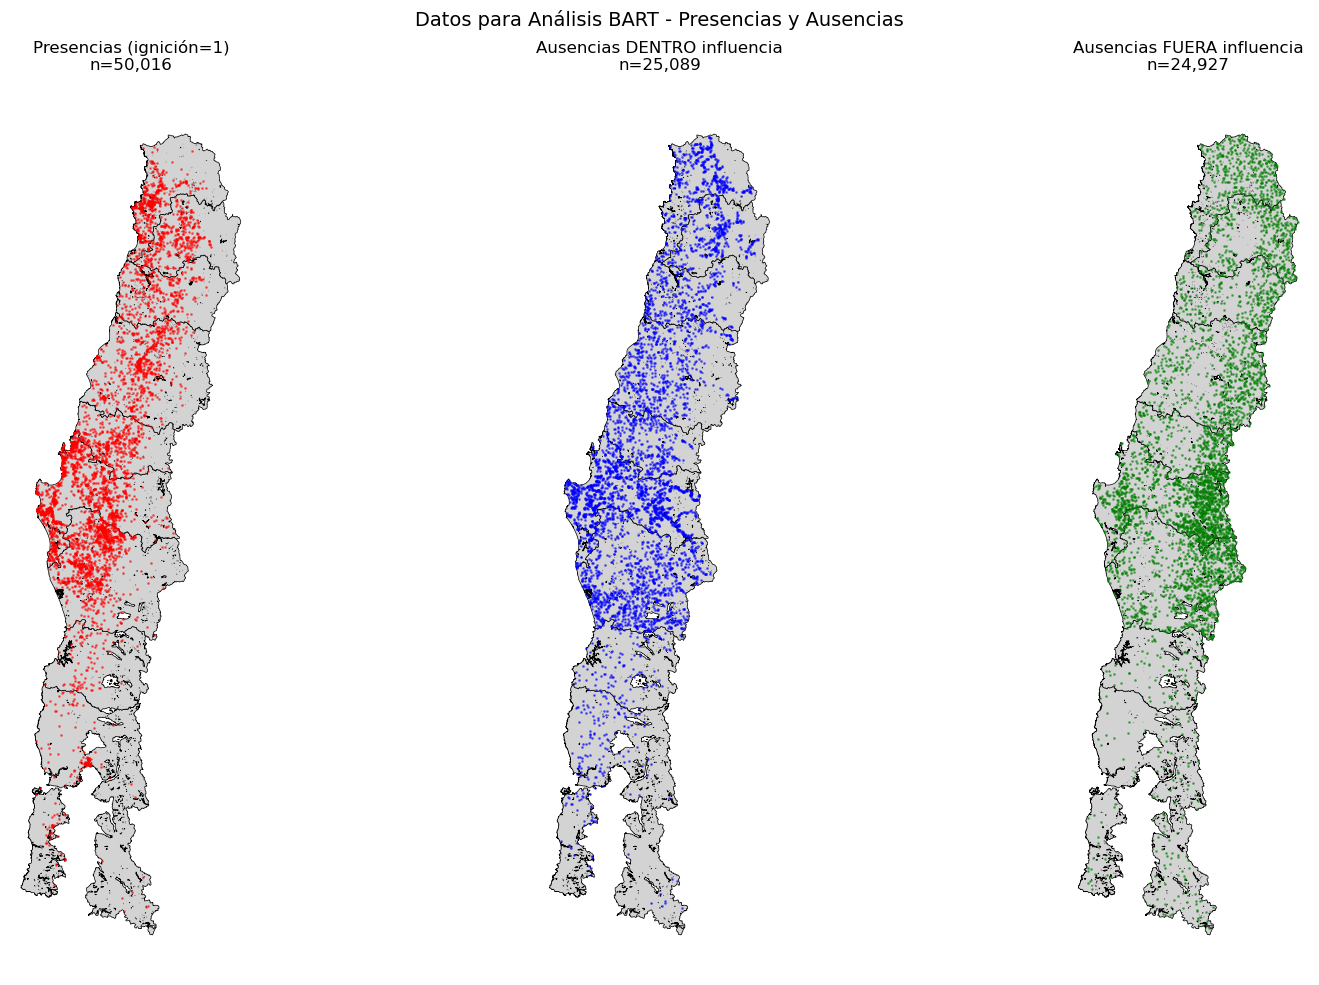

In [45]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fig, axes = plt.subplots(1, 3, figsize=(18, 10))

# Mapa 1: Presencias
temp_regiones_utm. plot(ax=axes[0], color='lightgray', edgecolor='black', linewidth=0.5)
gdf_presencias.sample(5000).plot(ax=axes[0], color='red', markersize=1, alpha=0.5)
axes[0].set_title(f'Presencias (ignición=1)\nn={len(gdf_presencias):,}', fontsize=12)
axes[0].set_axis_off()

# Mapa 2: Ausencias dentro de influencia
temp_regiones_utm.plot(ax=axes[1], color='lightgray', edgecolor='black', linewidth=0.5)
gdf_ausencias[gdf_ausencias['tipo_ausencia'] == 'dentro_influencia'].sample(min(5000, total_dentro)).plot(
    ax=axes[1], color='blue', markersize=1, alpha=0.5
)
axes[1].set_title(f'Ausencias DENTRO influencia\nn={total_dentro:,}', fontsize=12)
axes[1]. set_axis_off()

# Mapa 3: Ausencias fuera de influencia
temp_regiones_utm.plot(ax=axes[2], color='lightgray', edgecolor='black', linewidth=0.5)
gdf_ausencias[gdf_ausencias['tipo_ausencia'] == 'fuera_influencia'].sample(min(5000, total_fuera)). plot(
    ax=axes[2], color='green', markersize=1, alpha=0.5
)
axes[2]. set_title(f'Ausencias FUERA influencia\nn={total_fuera:,}', fontsize=12)
axes[2].set_axis_off()

plt.suptitle('Datos para Análisis BART - Presencias y Ausencias', fontsize=14)
plt.tight_layout()
plt.savefig("C:/Users/scray/Documentos/mapa_bart_v2.png", dpi=300, bbox_inches='tight')
plt.show()

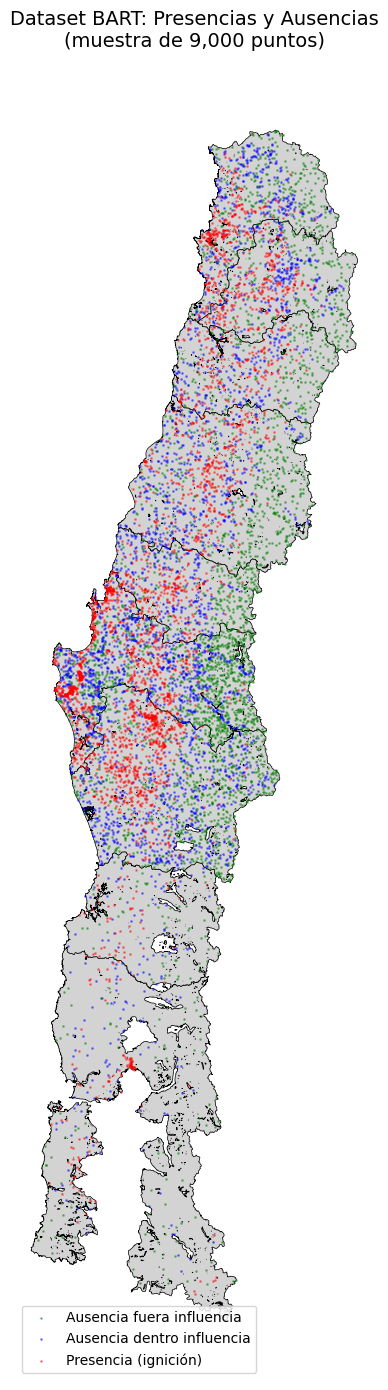

In [46]:
fig, ax = plt.subplots(figsize=(12, 14))

temp_regiones_utm.plot(ax=ax, color='lightgray', edgecolor='black', linewidth=0.5)

# Ausencias fuera (verde)
gdf_ausencias[gdf_ausencias['tipo_ausencia'] == 'fuera_influencia'].sample(3000).plot(
    ax=ax, color='green', markersize=1, alpha=0.4, label='Ausencia fuera influencia'
)

# Ausencias dentro (azul)
gdf_ausencias[gdf_ausencias['tipo_ausencia'] == 'dentro_influencia']. sample(3000).plot(
    ax=ax, color='blue', markersize=1, alpha=0.4, label='Ausencia dentro influencia'
)

# Presencias (rojo)
gdf_presencias. sample(3000).plot(
    ax=ax, color='red', markersize=1, alpha=0.4, label='Presencia (ignición)'
)

ax.legend(loc='lower left', fontsize=10)
ax.set_title('Dataset BART: Presencias y Ausencias\n(muestra de 9,000 puntos)', fontsize=14)
ax.set_axis_off()

plt.tight_layout()
plt.savefig("C:/Users/scray/Documentos/mapa_bart_combinado.png", dpi=300, bbox_inches='tight')
plt.show()

In [47]:
# Tabla cruzada de verificación
verificacion = pd.crosstab(
    gdf_bart['REGION'], 
    gdf_bart['tipo_ausencia'],
    margins=True
)
print("Distribución por región y tipo:")
print(verificacion)

Distribución por región y tipo:
tipo_ausencia  dentro_influencia  fuera_influencia  presencia     All
REGION                                                               
Biobio                      7404              7386      14790   29580
La Araucania                5474              5455      10929   21858
Los Lagos                    913               899       1812    3624
Los Rios                     473               459        932    1864
Maule                       3306              3290       6596   13192
Metropolitana               1756              1738       3494    6988
O'Higgins                   1550              1523       3073    6146
Valparaiso                  2292              2273       4565    9130
Ñuble                       1921              1904       3825    7650
All                        25089             24927      50016  100032
